# 05 — Feature selection: 05c, 05e and 05f on the corrected data (stage 7)

**Purpose.** Choose, for each target and horizon, the inputs of the tuned XGBoost (XGB-Opt), with
the method of the submitted report (§3.6): a base stage, SHAP backward elimination (05c), a
consensus of three methods (05e) and a robustness audit (05f). The report makes the 05e sets the
model input (D-13); 05f only audits them. The rebuild adds a check the original never made: each
05e set against the full pool, inside train and then once on validation (R7-04). Its outcome,
the input of stage 9, is `model_inputs.json` (section 10).

**Candidates.** The corrected contract of stage 6, the 22 candidates admitted
in stage 6b (D-12) and, for the indirect target, the history of k if it is admitted in section 1:
96 / 89 / 82 / 96 / 89 / 82 candidates (indirect D+1 to D+3, then direct).

**Rules (D-23, approved by the user).**
- The selection reads **train rows only** (manifest: train);
  validation is read at the end only (S8 only); the test split is never read.
- No quotas per category; the core of the original base stage (mapped to the new names) is kept
  through the base stage, as in the original.
- One score for every decision: nRMSE in kW (% of 3,449 kW) on held-out daytime
  hours of date folds inside train, 9,508 hours in both routes.
- The base stage runs separately for every target and horizon.
- **Selection model (R7-04, Q-17):** the fixed XGBoost of D-11 in both routes,
  400 trees, depth 6, learning rate
  0.05, 8 threads. Where two sets are compared: three seeds
  and the margin of the D-12 rule, max(0.05 pp, 2 × pooled seed std).

**In the original** (backup review, `00b_original_backup_review.ipynb`): the selection read the
whole table, validation and test included (F-26), and the direct selection kept the DC power of
the same hour (F-27). **Documented in** `docs/stage7_plan.md`, OP-46 to OP-48, run journal R7-01
to R7-05, errata F-29.

## 1. Does the history of k help the indirect target? (D-24)

In [1]:
import json

import pandas as pd
import yaml
from IPython.display import Image, display

from solarpv.config.paths import CONFIGS_DIR, OUTPUTS_DIR

OUT = OUTPUTS_DIR / "07_feature_selection"


def load(name):
    return json.loads((OUT / name).read_text(encoding="utf-8"))


display(pd.read_csv(OUT / "k_history_check.csv").round(3))
yaml.safe_load((CONFIGS_DIR / "k_history_decision.yaml").read_text(encoding="utf-8"))

,horizon,features,n_features,nrmse_kw_mean,nrmse_kw_std,seed_42,seed_123,seed_777
0,1,pool,96,7.626,0.009,7.621,7.636,7.620
1,1,pool+k_history,103,7.577,0.021,7.580,7.596,7.555
2,2,pool,89,7.943,0.032,7.946,7.909,7.973
3,2,pool+k_history,95,7.884,0.004,7.885,7.879,7.886
4,3,pool,82,8.262,0.030,8.246,8.297,8.244
5,3,pool+k_history,87,8.242,0.045,8.191,8.269,8.267


{'decision': 'D-24',
 'admitted': False,
 'results': {'indirect_D1': {'gain_pp': 0.0482,
   'margin_pp': 0.05,
   'passes': False},
  'indirect_D2': {'gain_pp': 0.059, 'margin_pp': 0.05, 'passes': True},
  'indirect_D3': {'gain_pp': 0.0199, 'margin_pp': 0.0761, 'passes': True}},
 'git_commit': '190e4df'}

**What it shows.** The fixed XGBoost of D-11, three seeds, on the date folds inside
train: the pool alone and the pool with the history of k (7 / 6 / 5 candidates at D+1 /
D+2 / D+3: lags of k known at issuance and same-hour rolling means).

**What it means.**
- **Gain of the k history:** 0.048 / 0.059 / 0.020 pp at D+1 / D+2 /
  D+3, against margins of 0.050 / 0.050 / 0.076 pp.
- **The rule (D-12, fixed before the run):** the gain at D+1 must exceed its margin, and D+2 and
  D+3 must not be worse by more than theirs. D+1 misses its margin by 0.002 pp.
- **Decision (D-24): not admitted.** The rule is applied as registered, even for a
  miss this small. The pools below contain no k history.

**In the original** the report shows `target_k_lag_1d` (§3.4), which is in no submitted set and
not in the XGB input (C-32): a text correction in v7.

## 2. The pipeline

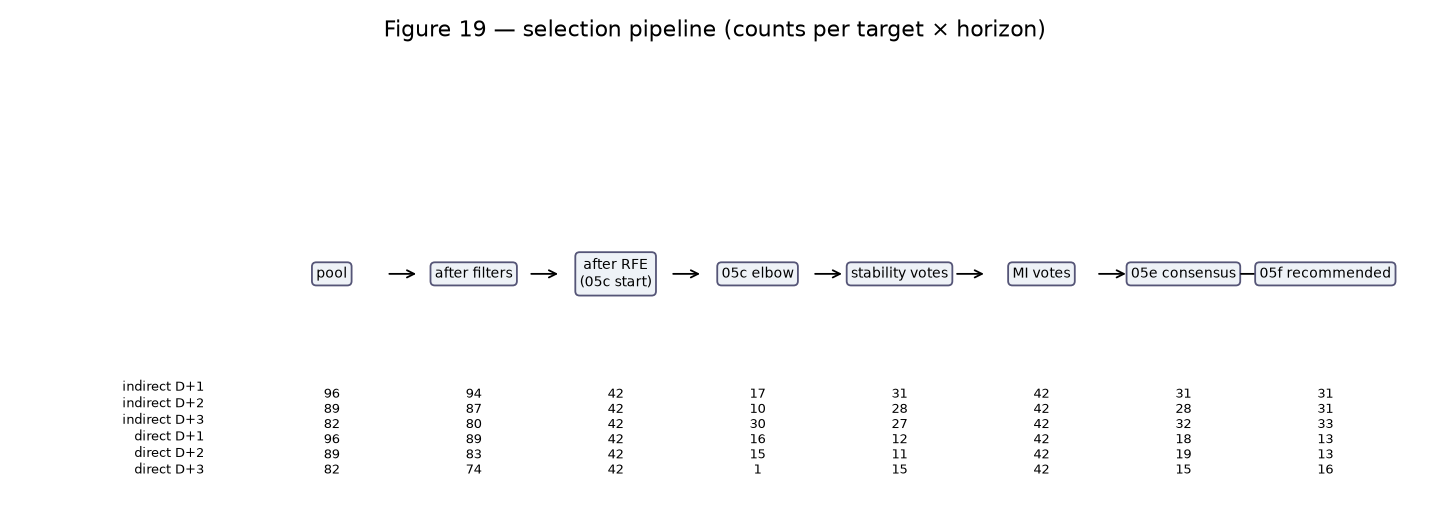

,pool,after filters,after RFE (05c start),05c elbow,stability votes,MI votes,05e consensus,05f recommended
indirect_D1,96,94,42,17,31,42,31,31
indirect_D2,89,87,42,10,28,42,28,31
indirect_D3,82,80,42,30,27,42,32,33
direct_D1,96,89,42,16,12,42,18,13
direct_D2,89,83,42,15,11,42,19,13
direct_D3,82,74,42,1,15,42,15,16


target                direct         indirect        
horizon                    1   2   3        1   2   3
pairs with |r| > 0.98     82  75  68       75  68  61

In [2]:
display(Image(str(OUT / "figures" / "fig19_pipeline.png")))
manifest = load("selection_manifest.json")
display(pd.DataFrame(manifest["counts"]).T)
pd.read_csv(OUT / "correlated_pairs.csv").groupby(["target", "horizon"]).size().rename(
    "pairs with |r| > 0.98").to_frame().T

**What it shows.** The number of features after each step, per target and horizon, and
the number of strongly correlated pairs.

**What it means.**
- **Pool:** 96 / 89 / 82 / 96 / 89 / 82 candidates (indirect D+1–D+3, then direct).
- **Filters (variance, MI; the core exempt):** down to
  94 / 87 / 80 / 89 / 83 / 74, all by the MI filter.
- **Correlated pairs:** 75 / 68 / 61 / 82 / 75 / 68 pairs with |r| > 0.98 are
  reported, not removed (R7-01: removing chained groups threw away real information). The RFE,
  one feature per step with a refit, removes redundant copies one at a time.
- **RFE:** each set to 42 / 42 / 42 / 42 / 42 / 42, as in the original.
- **05e consensus:** 31 / 28 / 32 / 18 / 19 / 15 features. In the submission:
  40 / 23 / 19 / 38 / 32 / 25.

## 3. 05c: SHAP backward elimination

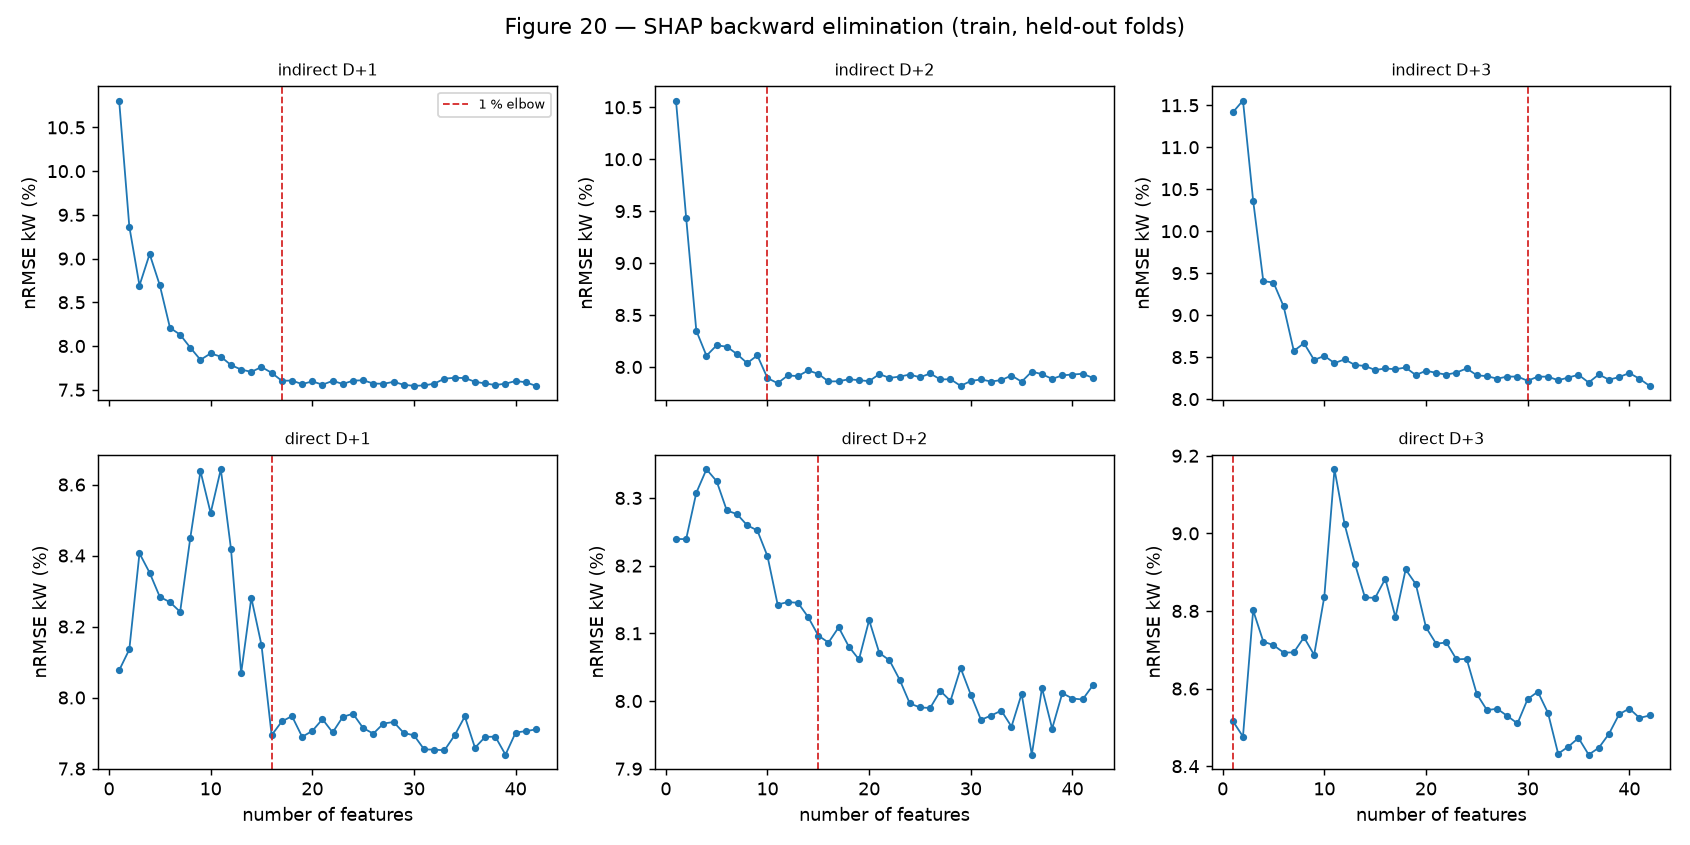

,indirect D+1,indirect D+2,indirect D+3,direct D+1,direct D+2,direct D+3
0.5pct,19,10,36,16,19,1
1.0pct,17,10,30,16,15,1
2.0pct,16,8,19,16,11,1
2nd_deriv,3,3,4,13,36,2


In [3]:
display(Image(str(OUT / "figures" / "fig20_shap_elimination.png")))
pd.DataFrame({f"{t} D+{h}": load(f"final_features_{t}_D{h}.json")["methods"]["shap_elbow"]
              ["elbows"] for t in ("indirect", "direct") for h in (1, 2, 3)})

**What it shows.** Starting from the 42 features of the base stage, the least
important feature (mean |SHAP| on held-out hours) is removed and the model refitted, down to one
feature. The curve is the nRMSE in kW on held-out train hours, one seed; the dashed line is the
1 % elbow, the smallest set within 1 % of the score of all 42.

**What it means.**
- **Elbow sizes (1 %):** 17 / 10 / 30 / 16 / 15 / 1.
- **Score of the 42 features (inner train):** indirect
  7.54 / 7.90 / 8.16 %, direct
  7.91 / 8.02 / 8.53 %.
- **The smallest elbow, direct D+3:** it keeps 1 feature,
  scoring 8.516 % against 8.531 % for
  all 42. There 1 % of the score is 0.085 pp, about one pooled seed std on
  the same folds (0.085 pp, half the margin of section 7). A one-seed curve cannot
  resolve that, so this elbow lies within the noise (F-29, section 8).

## 4. 05e: three votes and the consensus

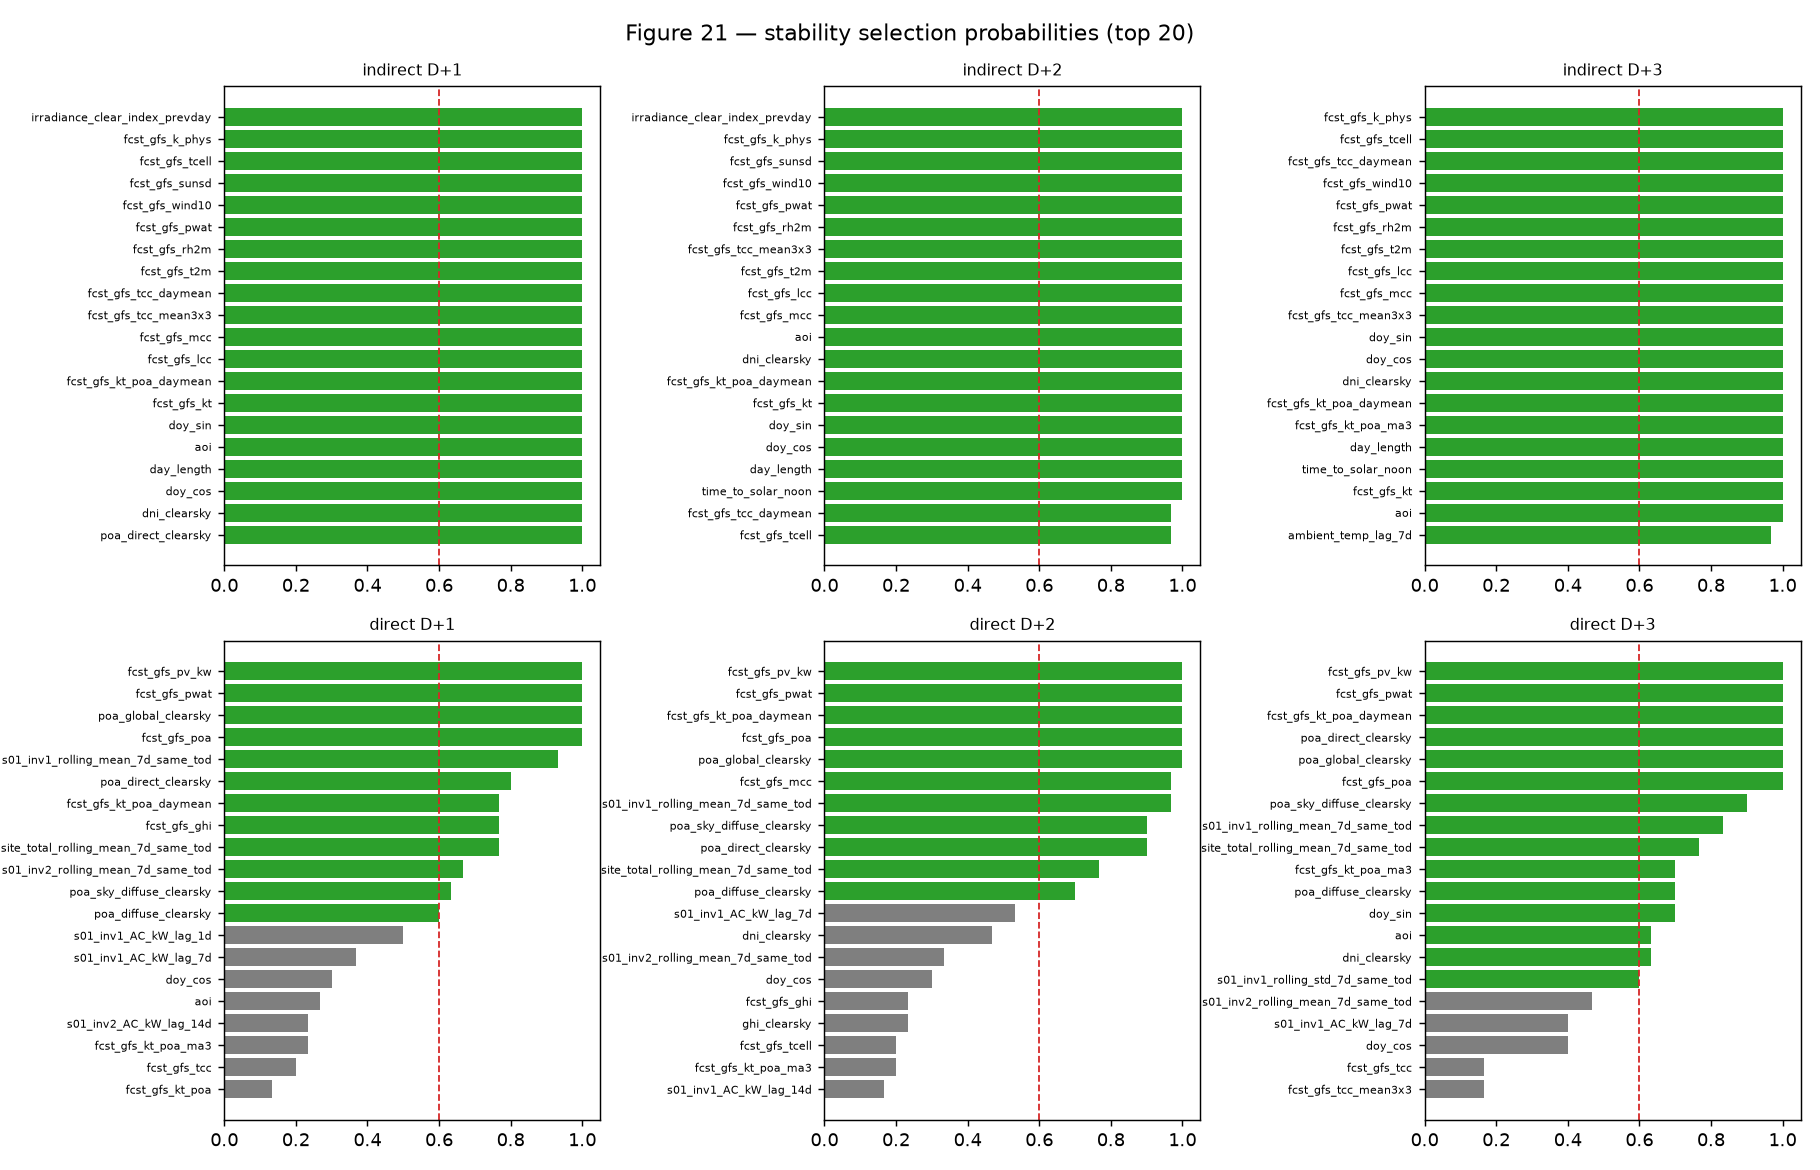

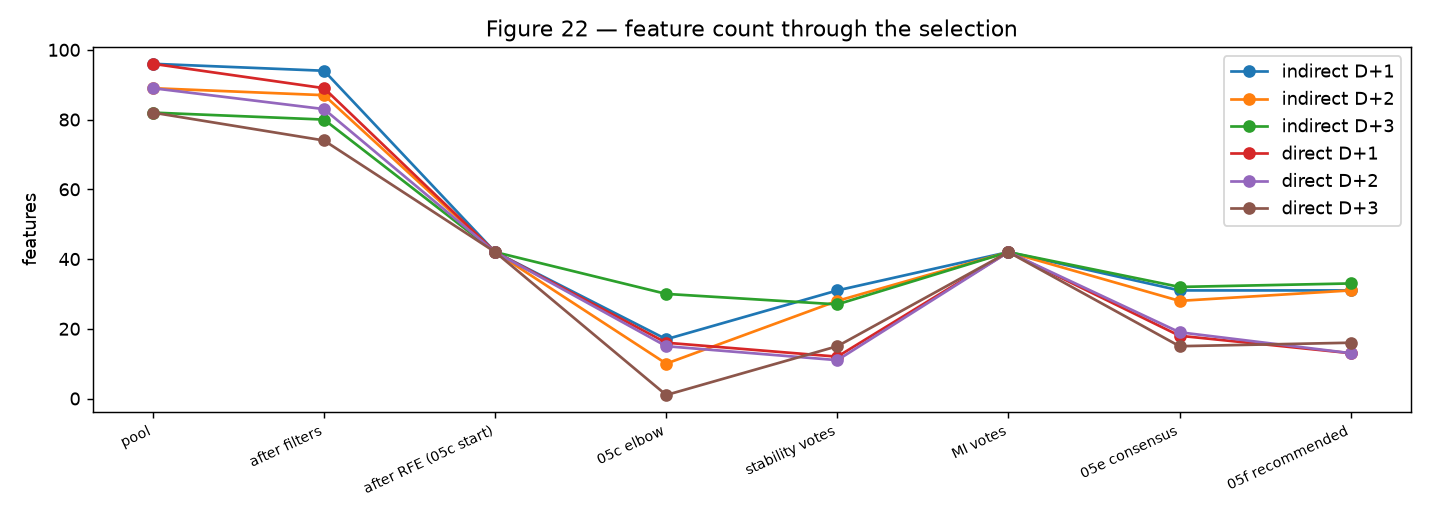

vote_shap  vote_stability  vote_mi  in_05e
target   horizon                                            
indirect 1               17              31       42      31
         2               10              28       42      28
         3               30              27       42      32
direct   1               16              12       42      18
         2               15              11       42      19
         3                1              15       42      15

In [4]:
display(Image(str(OUT / "figures" / "fig21_stability.png")))
display(Image(str(OUT / "figures" / "fig22_counts.png")))
votes = pd.read_csv(OUT / "selection_votes.csv")
cols = ["vote_shap", "vote_stability", "vote_mi", "in_05e"]
votes.groupby(["target", "horizon"], sort=False)[cols].sum()

**What it shows.** The selection probability of each feature over
30 subsamples of 70 % of the train days, and the number
of votes from each method.

**The three votes.**
- **SHAP:** the 05c elbow set.
- **Stability:** at least 1 % of the mean |SHAP| on the held-out days, in at
  least 60 % of the subsamples.
- **MI:** MI (sklearn, 5 neighbours) above the 95th percentile of the MI of 3 shuffled copies of every starting feature.

**What it means.**
- **Stability votes:** 31 / 28 / 27 / 12 / 11 / 15.
- **Consensus (2 of 3):** 31 / 28 / 32 / 18 / 19 / 15 features.
- **The MI vote, a limitation (R7-02):** it endorsed all 42 starting features in every
  set, because the MI filter of the base stage had already removed the features near the
  shuffled null. The consensus is therefore the union of the SHAP and stability votes. Kept as
  registered (D-23).

In [5]:
sets = {f"{t} D+{h}": load(f"final_features_{t}_D{h}.json")["recommended"]["features"]
        for t in ("indirect", "direct") for h in (1, 2, 3)}
pd.DataFrame({k: pd.Series(v) for k, v in sets.items()}).fillna("")

,indirect D+1,indirect D+2,indirect D+3,direct D+1,direct D+2,direct D+3
0,ghi_clearsky,dni_clearsky,ghi_clearsky,poa_global_clearsky,poa_global_clearsky,fcst_gfs_poa
1,dni_clearsky,aoi,dni_clearsky,poa_direct_clearsky,poa_diffuse_clearsky,dni_clearsky
2,ambient_temp_lag_1d,doy_sin,ambient_temp_lag_7d,poa_diffuse_clearsky,s01_inv1_rolling_mean_7d_same_tod,poa_global_clearsky
3,aoi,day_length,aoi,s01_inv1_rolling_mean_7d_same_tod,fcst_gfs_poa,poa_direct_clearsky
4,doy_sin,fcst_gfs_kt_poa_daymean,doy_sin,site_total_rolling_mean_7d_same_tod,fcst_gfs_kt_poa_daymean,poa_diffuse_clearsky
5,day_length,fcst_gfs_lcc,doy_cos,fcst_gfs_ghi,fcst_gfs_pwat,poa_sky_diffuse_clearsky
6,time_to_solar_noon,fcst_gfs_tcc_mean3x3,day_length,fcst_gfs_poa,fcst_gfs_pv_kw,s01_inv1_rolling_mean_7d_same_tod
7,fcst_gfs_kt_poa_daymean,fcst_gfs_t2m,time_to_solar_noon,fcst_gfs_kt_poa_daymean,ghi_clearsky,s01_inv1_rolling_std_7d_same_tod
8,fcst_gfs_tcc,fcst_gfs_pwat,fcst_gfs_kt,fcst_gfs_pwat,dhi_clearsky,site_total_rolling_mean_7d_same_tod
9,fcst_gfs_lcc,fcst_gfs_k_phys,fcst_gfs_kt_poa_ma3,fcst_gfs_pv_kw,poa_direct_clearsky,aoi


**What it shows.** The six 05e sets.

**What it means.**
- **GFS features:** 52 / 57 / 53 / 44 / 37 / 33 % of each set. They
  lead every SHAP ranking (05c): at least 2 of the top three in every set.
  - indirect D+1: `fcst_gfs_kt_poa_daymean`, `fcst_gfs_k_phys`, `fcst_gfs_pwat`
  - indirect D+2: `fcst_gfs_kt_poa_daymean`, `fcst_gfs_k_phys`, `fcst_gfs_pwat`
  - indirect D+3: `fcst_gfs_kt_poa_daymean`, `fcst_gfs_pwat`, `fcst_gfs_lcc`
  - direct D+1: `fcst_gfs_poa`, `fcst_gfs_pv_kw`, `fcst_gfs_ghi`
  - direct D+2: `fcst_gfs_poa`, `fcst_gfs_pv_kw`, `fcst_gfs_ghi`
  - direct D+3: `poa_global_clearsky`, `fcst_gfs_poa`, `fcst_gfs_pv_kw`
- **Lag features left:** 5 / 2 / 3 / 0 / 2 / 0 per set.
- **Red flags of the selection (plan §6):** no feature dominates the ranking, and every set
  keeps a GFS irradiance feature. The other two red flags of the plan, the order of the horizons
  and a set worse than the full pool, are examined in sections 7 and 9.
- **Use:** the indirect sets are the input of stage 9; the direct sets fail the check of
  section 7, and the direct route takes the full pool (section 10).

## 5. 05f: the robustness audit

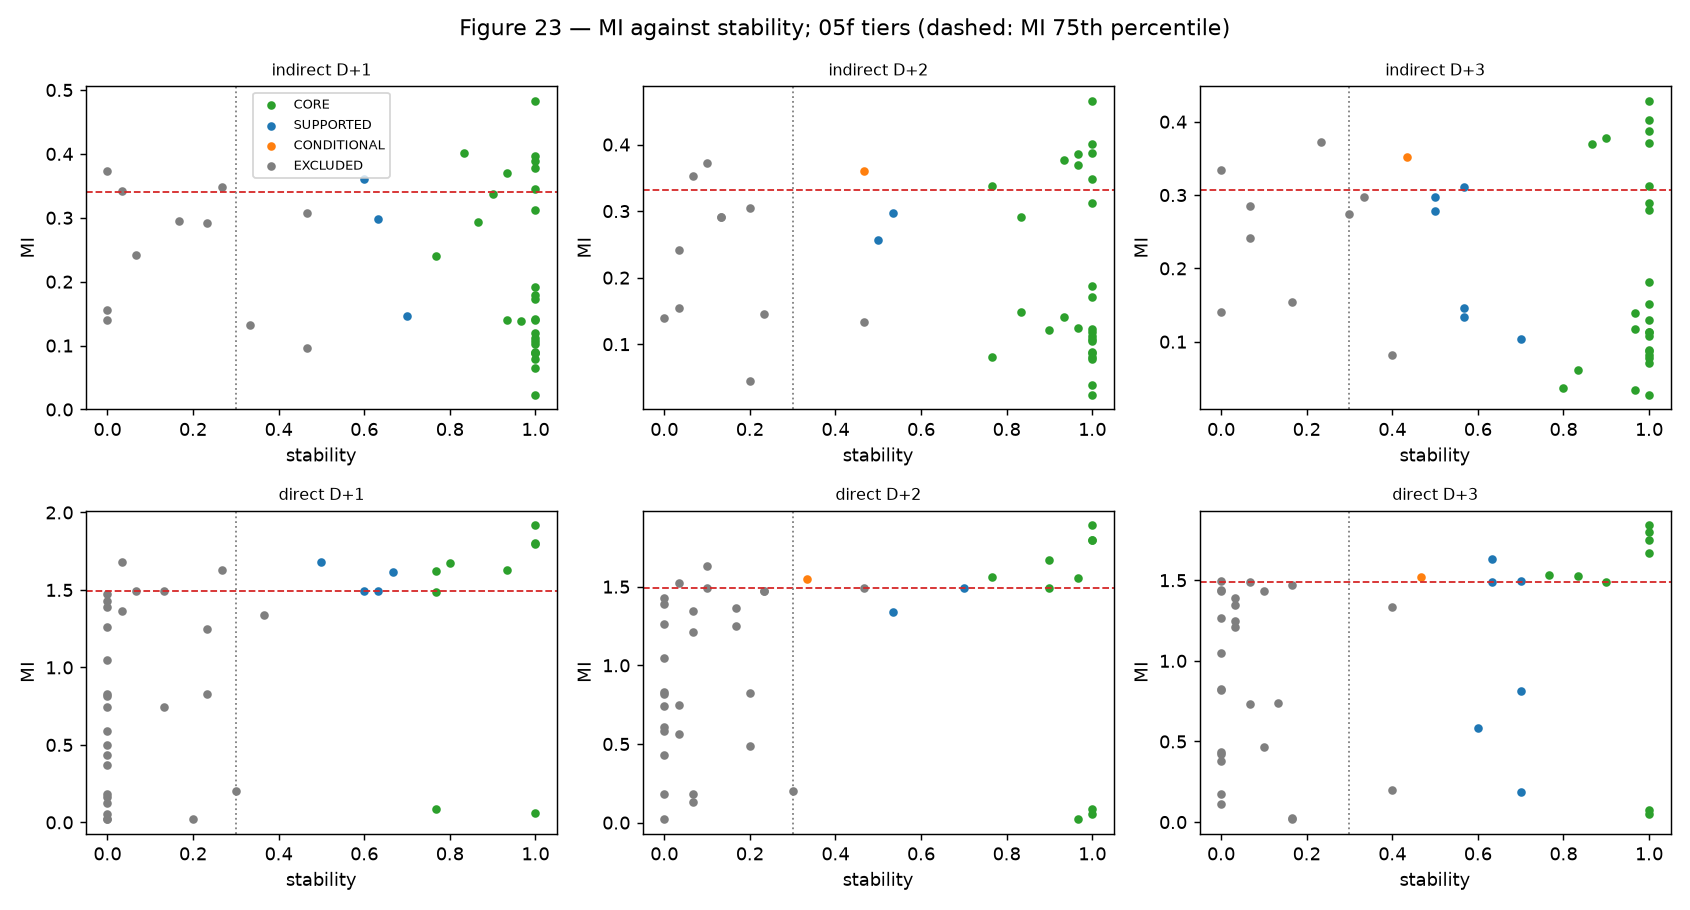

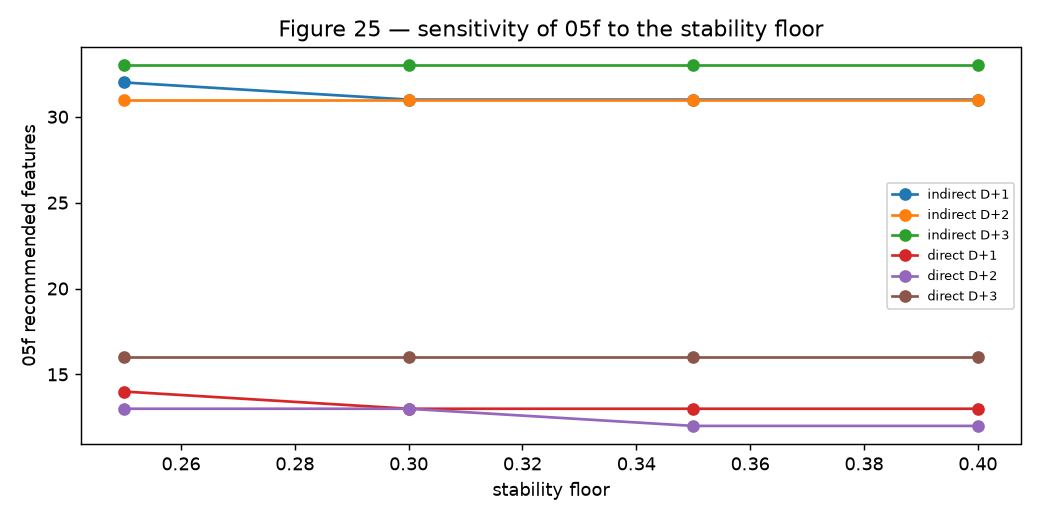

,indirect D+1,indirect D+2,indirect D+3,direct D+1,direct D+2,direct D+3
CORE,28,28,26,9,10,9
SUPPORTED,3,2,6,4,2,6
CONDITIONAL,0,1,1,0,1,1
EXCLUDED,11,11,9,29,29,26


In [6]:
display(Image(str(OUT / "figures" / "fig23_mi_stability.png")))
display(Image(str(OUT / "figures" / "fig25_floor_sensitivity.png")))
pd.DataFrame({f"{t} D+{h}": {tier: v["n"] for tier, v in load(
    f"refined_features_{t}_D{h}_05f.json")["tiers"].items()}
    for t in ("indirect", "direct") for h in (1, 2, 3)})

**What it shows.** Each of the 42 starting features placed by its stability and
its mutual information, in the four tiers of the submitted audit (CORE ≥
0.75, SUPPORTED ≥ 0.5, CONDITIONAL ≥
0.3 with MI above its 75th percentile, otherwise EXCLUDED), and the
number of recommended features for stability floors from 0.25 to 0.4.

**What it means.** 05f keeps 31 / 31 / 33 / 13 / 13 / 16 features
(CORE, SUPPORTED and CONDITIONAL). As in the original, the audit does not change the model input;
it shows which of the 05e features are robust.

## 6. Operational availability

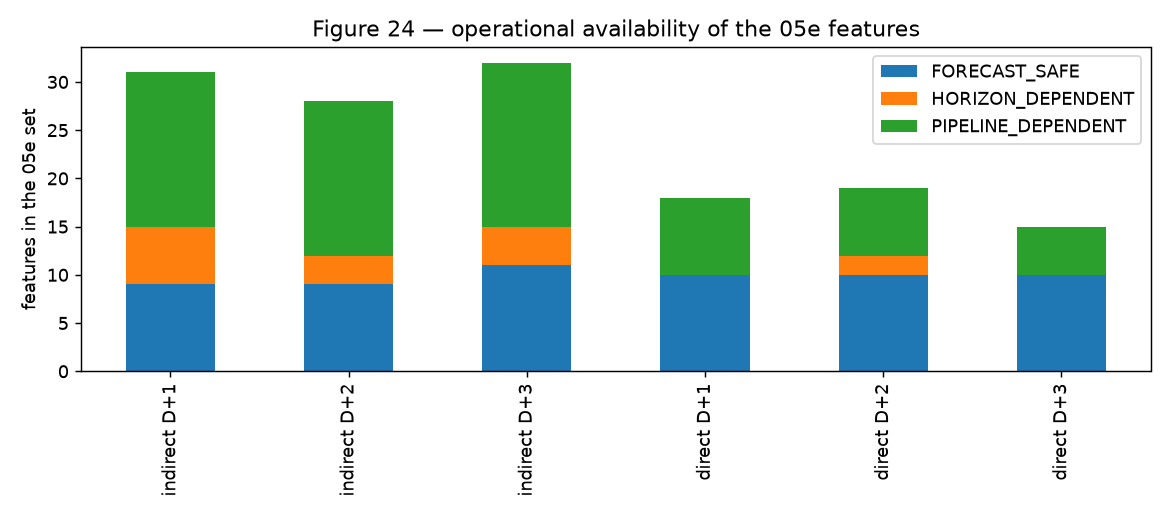

,feature,group,availability,indirect_D1,indirect_D2,indirect_D3,direct_D1,direct_D2,direct_D3
0,airmass,other,FORECAST_SAFE,False,False,False,True,False,False
1,ambient_temp_lag_14d,lag_power,HORIZON_DEPENDENT,False,False,True,False,False,False
2,ambient_temp_lag_1d,lag_power,HORIZON_DEPENDENT,True,False,False,False,False,False
3,ambient_temp_lag_2d,lag_power,HORIZON_DEPENDENT,False,True,False,False,False,False
4,ambient_temp_lag_3d,lag_power,HORIZON_DEPENDENT,True,False,True,False,False,False
5,ambient_temp_lag_7d,lag_power,HORIZON_DEPENDENT,True,True,True,False,False,False
6,aoi,other,FORECAST_SAFE,True,True,True,False,False,True
7,day_length,other,FORECAST_SAFE,True,True,True,False,False,False
8,dhi_clearsky,clearsky,FORECAST_SAFE,False,False,False,False,True,False
9,dni_clearsky,clearsky,FORECAST_SAFE,True,True,True,True,False,True


In [7]:
display(Image(str(OUT / "figures" / "fig24_availability.png")))
pd.read_csv(OUT / "feature_availability_classification.csv")

**What it shows.** The classes of the report (§3.6.6) for every feature that appears in a
05e set: FORECAST_SAFE (geometry, clear sky, time, rolling statistics), HORIZON_DEPENDENT (lags
and other histories) and PIPELINE_DEPENDENT (the GFS forecasts, which need the weather pipeline
running every day).

**What it means.** The columns show in which of the six sets each feature is used. The classes
of the stage-9 inputs, including the full pools of the direct route, are counted in section
10.

## 7. Each 05e set against the full pool, inside train (R7-04)

In [8]:
inner = pd.read_csv(OUT / "inner_train_check.csv")
inner.round(3)

,target,horizon,sample,n_05e,n_full,nrmse_05e,nrmse_full,05e_minus_full_pp,margin_pp,passes
0,indirect,1,date folds,31,96,7.568,7.626,-0.058,0.050,True
1,indirect,1,inner hold-out,31,96,7.258,7.270,-0.012,0.050,True
2,indirect,2,date folds,28,89,7.868,7.943,-0.074,0.081,True
3,indirect,2,inner hold-out,28,89,7.588,7.535,0.054,0.093,True
4,indirect,3,date folds,32,82,8.248,8.262,-0.014,0.053,True
5,indirect,3,inner hold-out,32,82,7.724,7.754,-0.029,0.067,True
6,direct,1,date folds,18,96,7.943,7.656,0.287,0.050,False
7,direct,1,inner hold-out,18,96,7.465,7.258,0.206,0.050,False
8,direct,2,date folds,19,89,8.046,7.945,0.102,0.064,False
9,direct,2,inner hold-out,19,89,7.718,7.587,0.131,0.070,False


**What it shows.** For every target and horizon, the fixed XGBoost of D-11 with three
seeds, trained once with the 05e set and once with the full pool, on two samples inside train:
the date folds, and an inner hold-out (fit to 2023-04-30, scored on the later
train days). The difference is 05e minus full pool, in pp of nRMSE. A set passes when on both
samples it is worse by at most the margin of the D-12 rule. The rule was written before the run
(`docs/stage7_plan.md` §7).

**What it means.**
- **Indirect: passes at every horizon** (date folds / inner hold-out):
  - indirect D+1: -0.058 / -0.012 pp, margins 0.050 / 0.050
  - indirect D+2: -0.074 / +0.054 pp, margins 0.081 / 0.093
  - indirect D+3: -0.014 / -0.029 pp, margins 0.053 / 0.067
- **Direct: fails at every horizon, on both samples:**
  - direct D+1: +0.287 / +0.206 pp, margins 0.050 / 0.050
  - direct D+2: +0.102 / +0.131 pp, margins 0.064 / 0.070
  - direct D+3: +0.714 / +0.202 pp, margins 0.170 / 0.082
- **Sanity:** the full-pool error rises with the horizon on both samples and in both routes:
  indirect 7.63 / 7.94 / 8.26 % on the date folds, direct
  7.66 / 7.94 / 8.35 %.

**Decision (R7-04 step 3).** A target and horizon that fails takes the full pool, and validation
is not used for it: the direct route takes the full pool at every horizon. The validation look
of section 9 ran at commit `ed78b59` (its run log), the commit that recorded this decision
before the look.

**Limit.** Both samples lie inside the rows the selection used, so this check can refute a set
but cannot prove it; validation is the real test (section 9).

## 8. Why the direct sets fail: concentrated importance (F-29)

In [9]:
votes["share"] = votes["shap_mean_abs"] / votes.groupby(["target", "horizon"])[
    "shap_mean_abs"].transform("sum")
rows = []
for (t, h), g in votes.groupby(["target", "horizon"], sort=False):
    top = g.sort_values("share", ascending=False)
    rows.append({"set": f"{t} D+{h}", "top 3 share %": 100 * top["share"].head(3).sum(),
                 "share >= 1 %": int((g["share"] >= 0.01).sum()),
                 "stability votes": int(g["vote_stability"].sum()),
                 "in 05e": int(g["in_05e"].sum()), "left out": int((~g["in_05e"]).sum()),
                 "share left out %": 100 * g.loc[~g["in_05e"], "share"].sum()})
pd.DataFrame(rows).round(1)

,set,top 3 share %,share >= 1 %,stability votes,in 05e,left out,share left out %
0,indirect D+1,31.2,34,31,31,11,10.4
1,indirect D+2,31.7,38,28,28,14,15.2
2,indirect D+3,27.6,35,27,32,10,8.8
3,direct D+1,64.5,15,12,18,24,14.1
4,direct D+2,54.4,16,11,19,23,14.7
5,direct D+3,37.0,19,15,15,27,29.1


**What it shows.** The share of each of the 42 starting features in their total
mean |SHAP| (`selection_votes.csv`), summarised per set.

**What it means.**
- **Top three features:** 64.5 / 54.4 / 37.0 % of the importance
  in the direct route, against 31.2 / 31.7 / 27.6 % in the indirect
  route. The direct top three:
  - direct D+1: `fcst_gfs_poa`, `fcst_gfs_pv_kw`, `fcst_gfs_ghi`
  - direct D+2: `fcst_gfs_poa`, `fcst_gfs_pv_kw`, `fcst_gfs_ghi`
  - direct D+3: `poa_global_clearsky`, `fcst_gfs_poa`, `fcst_gfs_pv_kw`
- **Features with at least 1 % of the importance:** 15 / 16 / 19 of 42 in
  the direct route, 34 / 38 / 35 in the indirect route. The stability vote needs that share on the
  held-out days, so it keeps
  12 / 11 / 15 direct features.
- **Left out of the direct 05e sets:** 24 / 23 / 27 starting features,
  which still carry 14.1 / 14.7 / 29.1 % of the importance
  together.

**Finding F-29.** In the direct route a few features hold most of the importance, so a relative
1 % share admits few features, and the one-seed 05c curve is too noisy to place
the elbow reliably (section 3). These are the registered rules (D-23), so this is a
limitation of the method, not a code bug; the larger selection model of R7-04 did not remove it.
The original pipeline never compared its 05e sets with the full pool, so it could not see it.

## 9. The third look at validation (R7-05)

In [10]:
val = pd.read_csv(OUT / "validation_check.csv")
val.round(3)

,target,horizon,features,n_features,nrmse_kw_mean,nrmse_kw_std,05e_minus_full_pp,margin_pp,red_flag
0,indirect,1,05e,31,6.836,0.012,0.021,0.050,False
1,indirect,1,full pool,96,6.814,0.024,0.021,0.050,False
2,direct,1,05e,18,6.829,0.027,-0.068,0.058,False
3,direct,1,full pool,96,6.897,0.031,-0.068,0.058,False
4,indirect,2,05e,28,7.257,0.020,-0.016,0.078,False
5,indirect,2,full pool,89,7.273,0.051,-0.016,0.078,False
6,direct,2,05e,19,7.277,0.047,0.192,0.101,True
7,direct,2,full pool,89,7.085,0.054,0.192,0.101,True
8,indirect,3,05e,32,6.708,0.085,0.033,0.122,False
9,indirect,3,full pool,82,6.675,0.013,0.033,0.122,False


**What it shows.** Trained on train and scored on validation: the fixed XGBoost of D-11,
three seeds, with the 05e set and with the full pool. The third look of stage 7 (the first two
were the laptop runs R7-01, void, and R7-02, with the same data); the test split is not read.

**What it means.**
- **Indirect, decided here:** 05e minus full pool
  +0.021 / -0.016 / +0.033 pp at D+1 / D+2 / D+3, against margins of
  0.050 / 0.078 / 0.122 pp. No red flag, so the input is the 05e set (D-13).
- **Direct, reported only** (decided in section 7): -0.068 / +0.192 / +0.378 pp
  against 0.058 / 0.101 / 0.089 pp. Red flags at D+2 and D+3, as inside
  train.
- **A limitation, the direct D+1 disagreement:** on validation the 05e set is
  0.068 pp better than the full pool (margin 0.058 pp), while inside train it
  was +0.287 / +0.206 pp worse. The
  registered rule decides, so the full pool stays; a choice made from this number would be a
  fourth look at validation.
- **Horizons on validation:** the full-pool error is
  6.81 / 7.27 / 6.67 % (indirect) and 6.90 / 7.08 / 6.63 %
  (direct), lower at D+3 than at D+1. This is the validation-sample effect examined in stage 6b
  (R6b-07, notebook `04c_nwp_gfs`); inside train the order is the expected one (section 7).

**In the original** the 05e sets were never compared with the full pool (F-29), and the
selection itself had read validation and test (F-26).

## 10. The input of stage 9 (`model_inputs.json`)

In [11]:
from solarpv.features.leakage import assert_no_leakage
from solarpv.selection.common import availability
from solarpv.selection.run import decide_input

classes = ["FORECAST_SAFE", "HORIZON_DEPENDENT", "PIPELINE_DEPENDENT"]
display({k: manifest[k] for k in ("splits_read_for_selection", "validation_read")})
inputs = load("model_inputs.json")
passes = inner.groupby(["target", "horizon"])["passes"].all()
flags = val.groupby(["target", "horizon"])["red_flag"].any()
rows = []
for k, d in inputs.items():
    t, h = k.split("_D")
    assert_no_leakage(d["features"])
    counts = pd.Series([availability(f) for f in d["features"]]).value_counts()
    rows.append({"set": f"{t} D+{h}", "source": d["source"], "n_features": d["n_features"],
                 "the rule gives": decide_input(passes[(t, int(h))], flags[(t, int(h))])[0],
                 **counts.reindex(classes, fill_value=0).to_dict()})
pd.DataFrame(rows)

{'splits_read_for_selection': ['train'], 'validation_read': 'S8 only'}

,set,source,n_features,the rule gives,FORECAST_SAFE,HORIZON_DEPENDENT,PIPELINE_DEPENDENT
0,indirect D+1,05e,31,05e,9,6,16
1,indirect D+2,05e,28,05e,9,3,16
2,indirect D+3,05e,32,05e,11,4,17
3,direct D+1,full pool,96,full pool,39,36,21
4,direct D+2,full pool,89,full pool,39,29,21
5,direct D+3,full pool,82,full pool,39,22,21


**What it shows.** The input of stage 9 for every target and horizon, the decision rule
of R7-04 recomputed from the two checks above, a leakage check of every input and its
availability classes.

**What it means.**
- **Indirect:** the 05e sets, 31 / 28 / 32 features.
- **Direct:** the full pool, 96 / 89 / 82 features.
- **The rule recomputed** gives the recorded source for all six; `assert_no_leakage` passes on
  every input.
- **Availability of the direct input:** 21 / 21 / 21
  GFS features (PIPELINE_DEPENDENT), 36 / 29 / 22
  histories (HORIZON_DEPENDENT) and 39 / 39 / 39
  FORECAST_SAFE features at D+1 / D+2 / D+3.
- **For the direct route this departs from D-13** (the 05e sets as the model input). The
  original XGBoost was trained on all its columns anyway, not on the 05e sets: its SHAP file has
  76 rows (C-31).

Stage 9 reads this file, not the 05e files.

## 11. Against the submitted selection

In [12]:
from solarpv.config.paths import EVIDENCE_DIR

base = pd.read_csv(OUT / "base_stage.csv")
rows = []
for t in ("indirect", "direct"):
    for h in (1, 2, 3):
        path = EVIDENCE_DIR / "09_feature_selection" / f"final_features_{t}_D{h}.json"
        old = json.loads(path.read_text(encoding="utf-8"))["recommended"]["features"]
        new = sets[f"{t} D+{h}"]
        pool = set(base.loc[(base["target"] == t) & (base["horizon"] == h), "feature"])
        rows.append({"set": f"{t} D+{h}", "submitted": len(old), "rebuild 05e": len(new),
                     "in both": len(set(old) & set(new)),
                     "submitted, in the rebuild pool": len(set(old) & pool),
                     "stage-9 input": inputs[f"{t}_D{h}"]["n_features"]})
pd.DataFrame(rows)

,set,submitted,rebuild 05e,in both,"submitted, in the rebuild pool",stage-9 input
0,indirect D+1,40,31,6,29,31
1,indirect D+2,23,28,4,16,28
2,indirect D+3,19,32,6,14,32
3,direct D+1,38,18,3,30,96
4,direct D+2,32,19,4,24,89
5,direct D+3,25,15,3,19,82


**What it shows.** The submitted 05e sets (`submission_evidence/09_feature_selection/`,
read-only) against the rebuild.

**What it means.**
- **Sizes:** submitted 40 / 23 / 19 (indirect) and
  38 / 32 / 25 (direct); rebuild 05e
  31 / 28 / 32 and
  18 / 19 / 15.
- **Few features in common:** 6 / 4 / 6 / 3 / 4 / 3. Of the submitted features, 29 / 16 / 14 / 30 / 24 / 19 exist in the
  rebuild pool at all.
- **The missing names:** 9 are the Open-Meteo weather columns and the forecasts
  derived from them (`fcst_cloud_cover`, `fcst_dhi`, `fcst_dni`, `fcst_ghi`, `fcst_temp_2m`, `fcst_wind_speed`, `poa_diffuse_forecast`, `poa_direct_forecast`, `poa_global_forecast`), values at the target hour rather than forecasts (F-11,
  F-28, C-09), replaced by GFS runs public before issuance. The others (`has_statistical_outlier`, `sun_azimuth`, `wind_speed_squared`) are not
  in the stage-6 contract.
- **The submitted direct sets** had the per-inverter DC power (`s01_inv1_DC_kW`, `s01_inv2_DC_kW`) removed only
  after the selection (F-27): their consensus had
  40 / 34 / 27 features.

**Conclusion.** The rebuild is not meant to reproduce the submitted sets (D-01): true UTC (F-01),
GFS forecasts available at issuance, and a selection on train only (F-26). The method of the
report (05c, 05e, 05f) is kept; the inside-train check is added.

**Next stage.** Stage 9 (`docs/stage9_plan.md`), with the inputs of section 10.

**Reproduce.** `python -m solarpv.selection.run --skip-validation` (about 93
minutes on the college machine), then `python -m solarpv.selection.run --validation-only`, then
`python scripts/make_feature_selection_notebook.py`.